In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import time

%matplotlib inline

%run ../sim_utilities.py


%load_ext autoreload
%autoreload 2

In [15]:
import bandits_lab.bandit_definitions as bands
import bandits_lab.algorithms as algs

0.6505863636931184
0.4


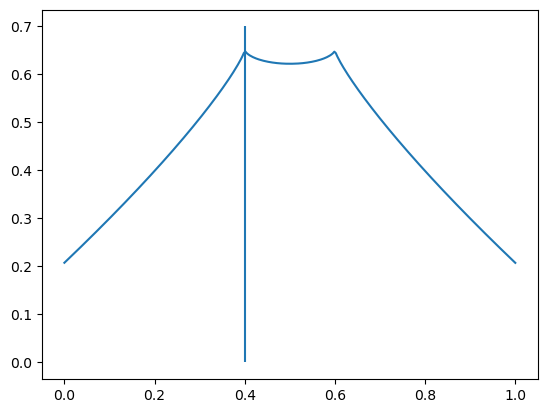

(array([500.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0., 499.]),
 array([0.4 , 0.42, 0.44, 0.46, 0.48, 0.5 , 0.52, 0.54, 0.56, 0.58, 0.6 ]),
 <BarContainer object of 10 artists>)

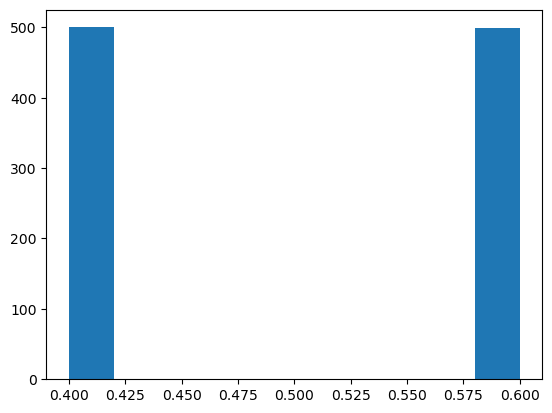

In [103]:
alpha = 3 / 4
bandit_problem = bands.ContBandPeak(alpha)
T = 1000

xs = np.linspace(0, 1, 300)
for _ in range(T):
    bandit_problem.play(0.5)


def phi(x):
    return bandit_problem.compute_cum_reward(x)


# xs = np.linspace(0, 1, 10000)
# phivals = [phi(x) for x in xs]
# print(np.argmax(phivals))


# max, xc = phi(0.3), 0.3
# level = 0.15
# for _ in range(20):
#     if phi(xc + level) > max:
#         max = phi(xc + level)
#         xc = xc + level
#     else:
#         xc = xc - level
#     level /= 2

xc = 0.4
plt.plot(xs, np.array([phi(x) for x in xs]) / T)
print(phi(xc) / T)
print(xc)
xstar = xc
plt.vlines(x=0.4, ymin=0, ymax=0.7)

plt.show()
plt.hist(bandit_problem.locations)

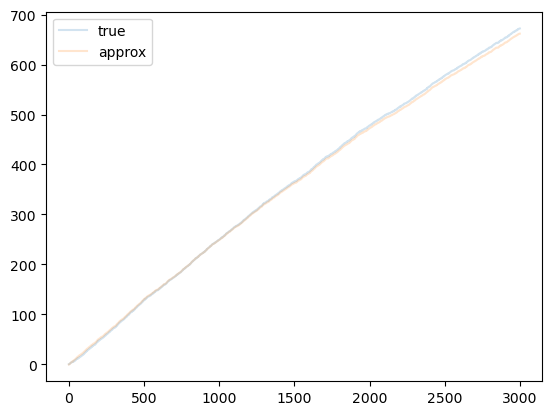

In [ ]:
K = 40
alpha = 3 / 4
bandit_problem = bands.ContBandPeak(alpha)
T = 3000
discrete_alg = algs.Exp3(K)

alg = algs.AbstractCAB(
    K=K,
    discrete_alg=discrete_alg,
    discretizer=algs.MidpointDiscretizer(K),
    label="Test1",
)

for t in range(T):
    arm = alg.choose_arm()
    reward = bandit_problem.play(arm)
    alg.update(reward)

rews = [bandit_problem.compute_tth_reward(xstar, t) for t in range(T)]

plt.plot(
    np.cumsum(rews) - np.cumsum(bandit_problem.observed_rewards),
    alpha=0.2,
    label="true",
)
plt.plot(
    np.arange(T) * 0.7017 - np.cumsum(bandit_problem.observed_rewards),
    alpha=0.2,
    label="approx",
)
plt.legend()

[1.53822610e-01 4.80167265e-01 4.93324055e-01 ... 1.28909175e+03
 1.28906594e+03 1.28934846e+03]


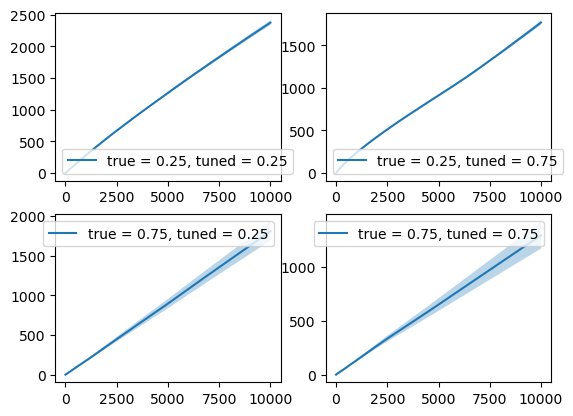

In [109]:
N = 100
T = 10_000
alpha = 1 / 4
beta = 3 / 4


def Kstar(T, alpha):
    return int(0.5 * np.power(T, 1 / (2 * alpha + 1)))


def sim(alpha, beta, T, N):
    results = np.zeros((T, N))
    K = Kstar(T, beta)
    for j in range(N):
        problem = bands.ContBandPeak(alpha)

        alg = algs.AbstractCAB(
            K=K,
            discrete_alg=algs.Exp3(K),
            discretizer=algs.MidpointDiscretizer(K),
        )

        for _ in range(T):
            arm = alg.choose_arm()
            reward = problem.play(arm)
            alg.update(reward)

        comp = np.cumsum([problem.compute_tth_reward(0.4, t) for t in range(T)])
        results[:, j] = comp - np.cumsum(problem.observed_rewards)
    return results


fig, axs = plt.subplots(2, 2)

for i, true_regularity in enumerate([alpha, beta]):
    for j, tuned_regularity in enumerate([alpha, beta]):
        results = sim(true_regularity, tuned_regularity, T, N)

        m_to_plot = np.mean(results, axis=-1)
        v_to_plot = np.sqrt(np.var(results, axis=-1) / N)

        axs[i, j].plot(
            m_to_plot, label=f"true = {true_regularity}, tuned = {tuned_regularity}"
        )
        axs[i, j].fill_between(
            np.arange(T),
            m_to_plot - v_to_plot,
            m_to_plot + v_to_plot,
            alpha=0.3,
        )
        axs[i, j].legend()
print(m_to_plot)


In [77]:
Ks = [-1]
Ts = [
    100,
    200,
    300,
    400,
    500,
    1000,
    2000,
    3000,
    4000,
    5000,
    6000,
    7000,
    8000,
    9000,
    10000,
    20000,
]  # , 10000]
N = 50

results = np.zeros((len(Ts), len(Ks), N))

for i, T in enumerate(Ts):
    for k, K in enumerate(Ks):
        if K == -1:
            K = int(np.power(T, 1 / (2 * alpha + 1)))
            print(k, K)
        for j in range(N):
            problem = bands.ContBandPeak(alpha)

            alg = algs.AbstractCAB(
                K=K,
                discrete_alg=algs.Exp3(K),
                discretizer=algs.MidpointDiscretizer(K),
                label=rf"{i}, {k}, {j}",
            )

            for t in range(T):
                arm = alg.choose_arm()
                reward = problem.play(arm)
                alg.update(reward)

            results[i, k, j] = T * 0.7017 - np.sum(problem.observed_rewards)

0 10
0 14
0 17
0 20
0 22
0 31
0 44
0 54
0 63
0 70
0 77
0 83
0 89
0 94
0 100
0 141


[[  37.5603709 ]
 [  68.18200182]
 [ 110.50375266]
 [ 142.83448685]
 [ 193.36675248]
 [ 363.37508084]
 [ 737.06130628]
 [1095.02446108]
 [1464.74659337]
 [1827.83077224]
 [2183.33365211]
 [2526.65858763]
 [2896.6387345 ]
 [3274.64631834]
 [3617.78429871]
 [7193.0396269 ]]


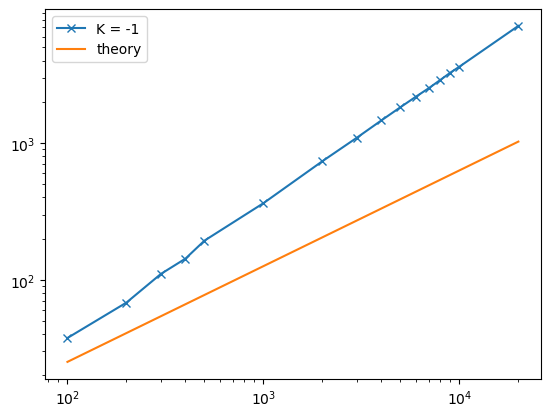

In [76]:
m_to_plot = np.mean(results, axis=2)
v_to_plot = np.sqrt(np.var(results, axis=2) / N)
for k, K in enumerate(Ks):
    plt.loglog(Ts, m_to_plot[:, k], "x-", label=f"K = {K}")
    plt.loglog(
        Ts,
        [np.power(T, 0.7 * (alpha + 1 / (2 * alpha + 1))) for T in Ts],
        label=f"theory",
    )
    plt.fill_between(
        Ts,
        m_to_plot[:, k] - v_to_plot[:, k],
        m_to_plot[:, k] + v_to_plot[:, k],
        alpha=0.3,
    )
print(m_to_plot)

plt.legend()

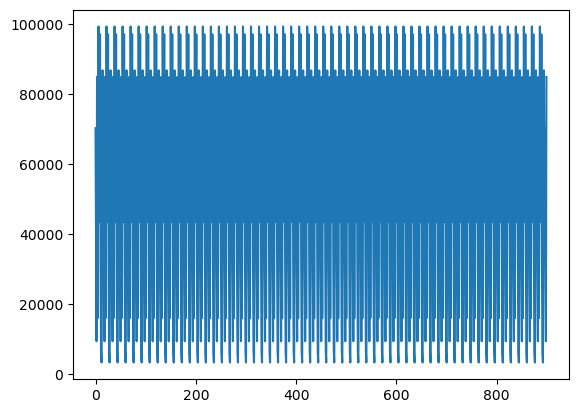

In [92]:
def bad_random_step(n):
    n2str = str(n**2)
    start_index = int(len(str(n2str)) / 4)
    # print(l)
    # print(n2str)
    return int(n2str[start_index : start_index + 5])


rngs = []
rng = 1337
for _ in range(1000):
    rng = bad_random_step(rng)
    rngs.append(rng)


plt.plot(rngs[100::])
